# Data Communications – Practice Lab Test
## Text Transmission Using 16-QAM — worked solution

**Goal:** encode a UTF-8 text message, map its bits to 16-QAM symbols, build a real passband waveform, recover the symbols with the supplied receiver, turn them back into text, and then see what noise (and, as an extra, attenuation and multipath) does to the link.

How this notebook is laid out:
* Each question has a **Markdown cell** that explains the reasoning and works through every calculation by hand.
* The **code cells** carry step-by-step comments so you can follow the thinking line by line.
* `qam_receiver_helpers.py` (the supplied helper code, copied exactly from the sheet) sits in the same folder.

## Step 0 – Create the helper file (needed on Google Colab)

The lab says `qam_receiver_helpers.py` must sit next to the notebook. Google Colab only uploads the notebook itself, so the cell below **writes the supplied helper code (copied exactly from the lab sheet) into that file**. Then the import in the Setup cell works anywhere: Colab, Jupyter or VS Code. If you already have the file, running this cell just overwrites it with identical code.

In [1]:
%%writefile qam_receiver_helpers.py
"""
Helper Code
Students may use these as black-box helpers. Their implementation is
not part of the assessment.
Functions:
- recover_symbols(rx_passband, fc, fs, samples_per_symbol)
- add_passband_awgn(signal, tx_symbols, samples_per_symbol, esn0_db, seed=2026)
"""
import numpy as np


def recover_symbols(rx_passband, fc, fs, samples_per_symbol):
    """Recover complex I+jQ symbol estimates from a real passband waveform.
    Assumes perfectly aligned symbols/carrier, and a whole number of
    carrier cycles per symbol. Returns one complex value per symbol.
    """
    signal = np.asarray(rx_passband, dtype=float)
    ns = int(samples_per_symbol)
    if ns <= 0 or signal.size % ns != 0:
        raise ValueError("Passband length must be a multiple of samples_per_symbol")
    t = np.arange(ns, dtype=float) / fs
    frames = signal.reshape(-1, ns)
    i = 2 * np.mean(frames * np.cos(2*np.pi*fc*t), axis=1)
    q = -2 * np.mean(frames * np.sin(2*np.pi*fc*t), axis=1)
    return i + 1j*q


def add_passband_awgn(signal, tx_symbols, samples_per_symbol, esn0_db, seed=2026):
    """Add real passband AWGN at a target symbol-energy-to-noise ratio.
    E_s/N_0 (dB) refers to the recovered complex constellation after
    coherent demodulation, not raw sample-level SNR.
    """
    signal = np.asarray(signal, dtype=float)
    symbols = np.asarray(tx_symbols, dtype=complex)
    if symbols.size == 0:
        raise ValueError("tx_symbols must not be empty")
    ns = int(samples_per_symbol)
    if ns <= 0 or signal.size != symbols.size*ns:
        raise ValueError("Expect exactly samples_per_symbol samples per tx symbol")
    es = float(np.mean(np.abs(symbols)**2))
    snr = 10 ** (float(esn0_db) / 10)
    variance = ns * es / (4 * snr)
    rng = np.random.default_rng(seed)
    return signal + rng.normal(0, np.sqrt(variance), size=signal.shape)

Overwriting qam_receiver_helpers.py


## Setup (provided; not assessed)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qam_receiver_helpers import recover_symbols, add_passband_awgn

# Gray-coded 2-bit -> amplitude map from the lab sheet.
# Neighbouring amplitudes differ in only ONE bit (00|01|11|10), so the most
# likely noise error (sliding to the adjacent level) costs just one bit.
level_map = {'00': -3, '01': -1, '11': 1, '10': 3}

# The four legal amplitudes on each axis, in ascending order.
levels = np.array([-3, -1, 1, 3])

# Extra (my own addition): the inverse map, amplitude -> 2-bit string. The receiver needs it.
inverse_level_map = {v: k for k, v in level_map.items()}

np.set_printoptions(precision=3, suppress=True)   # tidier printing of arrays
print('Ready')

Ready


---
## 1. Text Encoding

Message: **"Hello from the lab."**

**Reasoning**
1. A computer can't send characters, only numbers. UTF-8 is the rule that turns each character into one or more bytes (numbers from 0 to 255).
2. Every character in this message is plain ASCII (letters, a space, a full stop). ASCII characters take exactly **1 byte** each in UTF-8, so the byte count equals the character count.
3. Count the characters: `H e l l o` (5) + space (1) + `f r o m` (4) + space (1) + `t h e` (3) + space (1) + `l a b .` (4) = **19 characters → 19 bytes**.
4. Each byte is 8 bits, so we expect **19 × 8 = 152 bits**.

Worked example for the first byte: `'H'` has code 72. In binary, 72 = 64 + 8 = 2⁶ + 2³, which gives **`01001000`**.

In [3]:
# ---------- 1(a) text -> UTF-8 bytes ----------
message = "Hello from the lab."

# .encode('utf-8') returns a Python bytes object: one integer 0..255 per byte.
msg_bytes = message.encode('utf-8')

print("Message     :", repr(message))
print("UTF-8 bytes :", msg_bytes)
print("Byte values :", list(msg_bytes))           # decimal value of each byte
print("Hex         :", msg_bytes.hex(' '))         # same bytes in hex

Message     : 'Hello from the lab.'
UTF-8 bytes : b'Hello from the lab.'
Byte values : [72, 101, 108, 108, 111, 32, 102, 114, 111, 109, 32, 116, 104, 101, 32, 108, 97, 98, 46]
Hex         : 48 65 6c 6c 6f 20 66 72 6f 6d 20 74 68 65 20 6c 61 62 2e


In [4]:
# ---------- 1(b) bytes -> array of bits ----------
# np.unpackbits splits each uint8 into its 8 bits, most-significant bit first (MSB-first).
# MSB-first is the usual convention, and the receiver must use the same order later.
byte_array = np.frombuffer(msg_bytes, dtype=np.uint8)
bits = np.unpackbits(byte_array)                  # array of 0/1, dtype uint8

# Sanity check: rebuild the first byte by hand with f-string binary formatting.
print("First char 'H' = byte", msg_bytes[0], "=", format(msg_bytes[0], '08b'))
print("First 8 bits from unpackbits:", bits[:8])  # should match the line above

# Print every bit, grouped into bytes, so it's readable.
print("\nAll bits (grouped per byte):")
bit_str = ''.join(map(str, bits))
print(' '.join(bit_str[i:i+8] for i in range(0, len(bit_str), 8)))

First char 'H' = byte 72 = 01001000
First 8 bits from unpackbits: [0 1 0 0 1 0 0 0]

All bits (grouped per byte):
01001000 01100101 01101100 01101100 01101111 00100000 01100110 01110010 01101111 01101101 00100000 01110100 01101000 01100101 00100000 01101100 01100001 01100010 00101110


In [5]:
# ---------- 1(c) counts ----------
n_bytes = len(msg_bytes)       # 19 expected
n_bits  = bits.size            # 19 * 8 = 152 expected
print(f"Number of bytes: {n_bytes}")
print(f"Number of bits : {n_bits}  (= {n_bytes} bytes x 8 bits/byte)")
assert n_bits == 8 * n_bytes   # every byte gives exactly 8 bits

Number of bytes: 19
Number of bits : 152  (= 19 bytes x 8 bits/byte)


**1(c) Why the receiver must use the same character encoding**

The bits carry no meaning on their own. They are just numbers. The meaning comes from the **agreed encoding rule**. If the receiver decodes the same bytes with a different rule (say UTF-16, Latin-1 or EBCDIC), the **same bits** turn into **different characters**, or into errors.

Two examples:
* UTF-16 reads bytes in **pairs**. The 19 bytes would become ~9 unrelated characters, and the odd byte would be left over (a decode error).
* For non-ASCII text such as `'é'`, UTF-8 uses 2 bytes (`C3 A9`). A Latin-1 decoder reads each byte as its own character and prints `'Ã©'` ("mojibake").

So the transmitter and receiver must agree on: the encoding (UTF-8), the bit order (MSB first), and the 2-bit → amplitude map. Together these form part of the *protocol*.

---
## 2. 16-QAM Mapping and Constellation

**Reasoning**
* 16-QAM has **16 = 2⁴** distinct symbols, so each symbol carries **log₂16 = 4 bits**.
* For each 4-bit group `b₀b₁b₂b₃`: bits `b₀b₁` pick the **I** (in-phase) amplitude, bits `b₂b₃` pick the **Q** (quadrature) amplitude, and the symbol is **s = I + jQ**.
* Number of symbols = 152 bits ÷ 4 bits/symbol = **38 symbols**. 152 divides evenly by 4, so no padding is needed.

**Worked example (first character 'H' = `01001000`):**

| 4-bit group | I bits → I | Q bits → Q | Symbol |
|---|---|---|---|
| `0100` | `01` → −1 | `00` → −3 | **−1 − 3j** |
| `1000` | `10` → +3 | `00` → −3 | **+3 − 3j** |

So 'H' becomes two symbols: −1−3j, then 3−3j.

In [6]:
# ---------- 2(a) group bits in fours and map to complex symbols ----------
BITS_PER_SYMBOL = 4

# Defensive padding: pad with zeros if the bit count isn't a multiple of 4.
# Here 152 % 4 == 0, so pad_len is 0. We still keep n_bits so the receiver
# can trim any padding back off.
pad_len = (-n_bits) % BITS_PER_SYMBOL
tx_bits = np.concatenate([bits, np.zeros(pad_len, dtype=np.uint8)])
print("Padding bits added:", pad_len)

# Reshape into rows of 4: row k holds the 4 bits of symbol k.
groups = tx_bits.reshape(-1, BITS_PER_SYMBOL)

symbols = []
for g in groups:
    i_bits = f"{g[0]}{g[1]}"          # first two bits  -> I
    q_bits = f"{g[2]}{g[3]}"          # last two bits   -> Q
    I = level_map[i_bits]             # look up the amplitude
    Q = level_map[q_bits]
    symbols.append(I + 1j * Q)        # complex symbol I + jQ
symbols = np.array(symbols, dtype=complex)

# Show the first few groups alongside their symbols to check against the hand-worked table.
for k in range(6):
    print(f"symbol {k}: bits {''.join(map(str, groups[k]))} -> {symbols[k]}")
print("...")
print(f"Total symbols: {symbols.size}")

Padding bits added: 0
symbol 0: bits 0100 -> (-1-3j)
symbol 1: bits 1000 -> (3-3j)
symbol 2: bits 0110 -> (-1+3j)
symbol 3: bits 0101 -> (-1-1j)
symbol 4: bits 0110 -> (-1+3j)
symbol 5: bits 1100 -> (1-3j)
...
Total symbols: 38


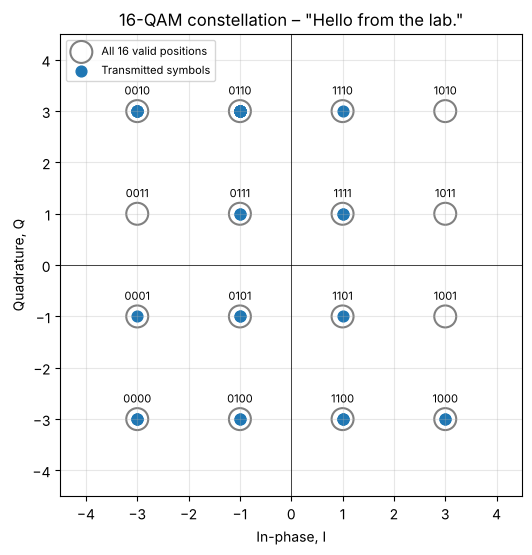

Distinct constellation points actually used: 12 of 16


In [7]:
# ---------- 2(b) constellation plot ----------
# Every valid 16-QAM point is a combination of one I level and one Q level.
I_grid, Q_grid = np.meshgrid(levels, levels)
ref_points = (I_grid + 1j * Q_grid).ravel()      # 16 reference points

fig, ax = plt.subplots(figsize=(6, 6))
# Reference grid: hollow grey circles so you can see which points are used.
ax.scatter(ref_points.real, ref_points.imag, s=250, facecolors='none',
           edgecolors='grey', linewidths=1.5, label='All 16 valid positions')
# Transmitted symbols on top. Many repeat, so we only see the distinct ones.
ax.scatter(symbols.real, symbols.imag, s=60, color='tab:blue',
           label='Transmitted symbols')

# Label every reference point with its 4-bit code (I bits then Q bits).
for p in ref_points:
    code_str = inverse_level_map[int(p.real)] + inverse_level_map[int(p.imag)]
    ax.annotate(code_str, (p.real, p.imag), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=8)

ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
ax.set_xlabel('In-phase, I'); ax.set_ylabel('Quadrature, Q')
ax.set_title('16-QAM constellation – "Hello from the lab."')
ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5)
ax.set_aspect('equal')              # square scale, so distances aren't distorted
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left', fontsize=8)
plt.show()

used = np.unique(symbols)
print(f"Distinct constellation points actually used: {used.size} of 16")

**2(c)** Number of symbols = **152 / 4 = 38**.

**Why 16-QAM carries 4 bits per symbol:** the receiver tells symbols apart by their position. With *M* distinguishable positions, one symbol can encode one of *M* possibilities, which is log₂*M* bits of information. Here *M* = 16 (4 I levels × 4 Q levels), and **log₂16 = 4**. Put another way: 4 amplitude levels on I give 2 bits (2² = 4), and 4 independent levels on Q give another 2 bits, so 2 + 2 = 4 bits.

(Not all 16 points appear in the plot, because ASCII text doesn't use every bit pattern. For example, ASCII bytes always start with bit 0, which limits the first symbol of each byte.)

---
## 3. Passband Modulation

**Converting the given values to SI units first**

| Quantity | Given | SI value |
|---|---|---|
| Carrier frequency *f_c* | 0.2 MHz | 0.2 × 10⁶ = **200 000 Hz** |
| Sampling frequency *f_s* | 25 000 kHz | 25 000 × 10³ = **25 × 10⁶ Hz** (25 MHz) |
| Symbol duration *T_s* | 4 µs | **4 × 10⁻⁶ s** |

**Samples per symbol:** N_s = f_s × T_s = 25×10⁶ × 4×10⁻⁶ = **100 samples**.
**Sample spacing:** Δt = 1/f_s = 1/25×10⁶ = **40 ns**.
Time array for one symbol: t = 0, 40 ns, 80 ns, …, 99 × 40 ns = 3.96 µs. That is `np.arange(Ns)/fs`, which runs from 0 up to (but not including) T_s.

**Waveform for symbol k:** x_k(t) = I_k cos(2π f_c t) − Q_k sin(2π f_c t), for 0 ≤ t < T_s.

The equation restarts *t* at 0 for every symbol. The supplied receiver also uses the same local `t = np.arange(ns)/fs` for every frame, so we build each symbol over the **same local time array** and join the pieces end to end.

Sanity check on the oscillator: f_s / f_c = 25×10⁶ / 2×10⁵ = **125 samples per carrier cycle**. That is far above the Nyquist minimum of 2, so the carrier is well sampled.

In [8]:
# ---------- 3(a) parameters and one-symbol time array ----------
fc = 0.2e6          # carrier frequency: 0.2 MHz  -> 200 000 Hz
fs = 25_000e3       # sampling frequency: 25 000 kHz -> 25 000 000 Hz
Ts = 4e-6           # symbol duration: 4 microseconds

# Samples per symbol = fs * Ts. Use round() before int() so floating-point
# error (e.g. 99.99999999) can't truncate to the wrong integer.
Ns = int(round(fs * Ts))

# Local time axis for ONE symbol: 0, 1/fs, 2/fs, ..., (Ns-1)/fs
t_sym = np.arange(Ns) / fs

print(f"fc = {fc:.0f} Hz, fs = {fs:.0f} Hz, Ts = {Ts*1e6:.1f} us")
print(f"Samples per symbol Ns = fs*Ts = {fs:.0f} * {Ts} = {Ns}")
print(f"Sample spacing 1/fs   = {1/fs*1e9:.0f} ns")
print(f"t_sym runs from {t_sym[0]*1e6:.2f} us to {t_sym[-1]*1e6:.2f} us ({t_sym.size} points)")

fc = 200000 Hz, fs = 25000000 Hz, Ts = 4.0 us
Samples per symbol Ns = fs*Ts = 25000000 * 4e-06 = 100
Sample spacing 1/fs   = 40 ns
t_sym runs from 0.00 us to 3.96 us (100 points)


In [9]:
# ---------- 3(b) full passband waveform ----------
# The carrier waveforms are the same for every symbol (same local t), so compute them once.
cos_c = np.cos(2 * np.pi * fc * t_sym)
sin_c = np.sin(2 * np.pi * fc * t_sym)

# Vectorised: build a (num_symbols x Ns) array. Row k is
#     x_k(t) = I_k*cos(2*pi*fc*t) - Q_k*sin(2*pi*fc*t)
# symbols.real[:, None] turns I into a column so it broadcasts across the 100 samples.
tx_frames = symbols.real[:, None] * cos_c - symbols.imag[:, None] * sin_c

# Flatten row by row into one long real-valued signal: symbol 0, then symbol 1, and so on.
tx_passband = tx_frames.ravel()

# Matching global time axis for plotting.
t_total = np.arange(tx_passband.size) / fs

print("Waveform is real-valued:", np.isrealobj(tx_passband))
print(f"Total samples = {symbols.size} symbols x {Ns} = {tx_passband.size}")
print(f"Total duration = {t_total[-1]*1e6 + 1/fs*1e6:.0f} us (= 38 x 4 us = 152 us)")

Waveform is real-valued: True
Total samples = 38 symbols x 100 = 3800
Total duration = 152 us (= 38 x 4 us = 152 us)


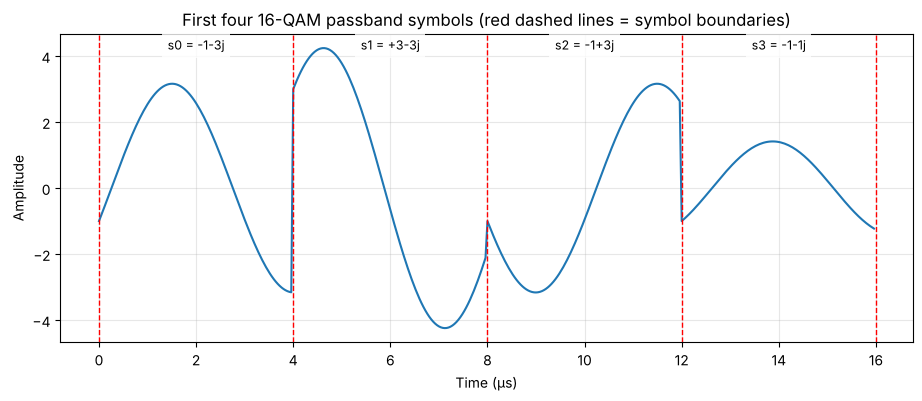

In [10]:
# ---------- 3(c) plot the first four symbols ----------
n_show = 4
seg = slice(0, n_show * Ns)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t_total[seg] * 1e6, tx_passband[seg], lw=1.5, label='Passband x(t)')

# Dashed vertical lines at every symbol boundary t = k*Ts.
for k in range(n_show + 1):
    ax.axvline(k * Ts * 1e6, color='red', ls='--', lw=1)
# Write each symbol's I+jQ value above its slot so the shape can be matched to its symbol.
for k in range(n_show):
    s = symbols[k]
    ax.text((k + 0.5) * Ts * 1e6, ax.get_ylim()[1] * 0.9,
            f"s{k} = {int(s.real):+d}{int(s.imag):+d}j", ha='center', fontsize=9,
            bbox=dict(fc='white', ec='none', alpha=0.8))

ax.set_xlabel('Time (µs)'); ax.set_ylabel('Amplitude')
ax.set_title('First four 16-QAM passband symbols (red dashed lines = symbol boundaries)')
ax.grid(True, alpha=0.3)
plt.show()

**What the plot shows:** at t = 0 of each symbol, cos = 1 and sin = 0, so x_k(0) = I_k. Each slot therefore *starts* at its I value (−1, +3, −1, −1 for the first four). The shape then depends on both I and Q. Because each symbol is only 0.8 of a carrier cycle long (see 3(d)), you only see part of a sine wave per slot, and the waveform **jumps** at most boundaries where the next symbol starts.

---
**3(d) Rates and carrier cycles**

* **Symbol rate:** R_s = 1/T_s = 1 / 4×10⁻⁶ = **250 000 symbols/s = 250 kBd**
* **Bit rate:** R_b = R_s × bits/symbol = 250 000 × 4 = **1 000 000 bit/s = 1 Mbit/s**
* **Carrier cycles per symbol:** f_c × T_s = 2×10⁵ × 4×10⁻⁶ = **0.8 cycles**

Time to send the whole message: 38 symbols × 4 µs = 152 µs. Check: 152 bits ÷ 1 Mbit/s = 152 µs ✔.

In [11]:
# ---------- 3(d) numbers checked in code ----------
Rs = 1 / Ts                         # symbols per second
Rb = Rs * BITS_PER_SYMBOL           # bits per second
cycles_per_symbol = fc * Ts         # how much of a carrier period fits in one symbol

print(f"Symbol rate  Rs = 1/Ts        = {Rs:,.0f} symbols/s ({Rs/1e3:.0f} kBd)")
print(f"Bit rate     Rb = Rs x 4      = {Rb:,.0f} bit/s ({Rb/1e6:.0f} Mbit/s)")
print(f"Carrier cycles per symbol fc*Ts = {cycles_per_symbol:.2f}")
print(f"Whole number of cycles? {np.isclose(cycles_per_symbol, round(cycles_per_symbol))}")

Symbol rate  Rs = 1/Ts        = 250,000 symbols/s (250 kBd)
Bit rate     Rb = Rs x 4      = 1,000,000 bit/s (1 Mbit/s)
Carrier cycles per symbol fc*Ts = 0.80
Whole number of cycles? False


> ⚠️ **Important observation.** The helper's docstring says `recover_symbols` *"assumes … a whole number of carrier cycles per symbol."* With these parameters there are only **0.8 cycles**, so that assumption **is broken**. We should expect the recovered symbols to come out *not exactly* equal to the originals. Question 4 measures this effect and explains it.

---
## 4. Demodulation and Text Recovery

In [12]:
# ---------- 4(a) call the supplied receiver ----------
rx_symbols = recover_symbols(tx_passband, fc, fs, Ns)

print(f"Recovered {rx_symbols.size} symbols (expected {symbols.size})\n")
print(f"{'k':>2} | {'original':>10} | {'recovered':>18} | {'error |rx-tx|':>13}")
for k in range(5):
    print(f"{k:>2} | {str(symbols[k]):>10} | {rx_symbols[k].real:+.3f}{rx_symbols[k].imag:+.3f}j"
          f"   | {abs(rx_symbols[k]-symbols[k]):>13.3f}")
print(f"\nLargest error over all symbols: {np.max(np.abs(rx_symbols - symbols)):.3f}")

Recovered 38 symbols (expected 38)

 k |   original |          recovered | error |rx-tx|
 0 |    (-1-3j) | -0.402-2.965j   |         0.599
 1 |     (3-3j) | +3.400-3.696j   |         0.803
 2 |    (-1+3j) | -1.499+3.331j   |         0.599
 3 |    (-1-1j) | -0.768-0.867j   |         0.268
 4 |    (-1+3j) | -1.499+3.331j   |         0.599

Largest error over all symbols: 0.803


**4(a) Comparison.** The recovered values are **close to, but not equal to**, the originals (errors up to about 0.8). Even with **no noise at all**, the receiver is distorting the symbols. This comes from the 0.8-cycle issue flagged above. The cell below shows exactly why.

**Why it happens (optional deeper explanation).** The receiver multiplies by cos and −sin, averages over one symbol, and doubles:

Î = 2·mean(x·cos) = I·**2⟨cos²⟩** − Q·**2⟨sin·cos⟩**
Q̂ = −2·mean(x·sin) = −I·**2⟨sin·cos⟩** + Q·**2⟨sin²⟩**

* With a **whole** number of cycles, ⟨cos²⟩ = ⟨sin²⟩ = ½ and ⟨sin·cos⟩ = 0. You get Î = I and Q̂ = Q exactly.
* With **0.8** cycles, these averages are not ½ and 0. The I and Q channels get the wrong gain **and leak into each other** (crosstalk).

In [13]:
# Measure the three averages the receiver effectively uses, over our 0.8-cycle symbol.
a = 2 * np.mean(cos_c**2)          # gain applied to I in the I output (ideal 1)
b = 2 * np.mean(sin_c * cos_c)     # crosstalk term (ideal 0)
c = 2 * np.mean(sin_c**2)          # gain applied to Q in the Q output (ideal 1)
print(f"2<cos^2>   = {a:.3f}   (ideal 1)")
print(f"2<sin cos> = {b:.3f}   (ideal 0)")
print(f"2<sin^2>   = {c:.3f}   (ideal 1)")

# Predict the recovered symbol from the formula and check it against the helper's output.
pred = (a*symbols.real - b*symbols.imag) + 1j*(-b*symbols.real + c*symbols.imag)
print("Formula predicts the helper output exactly:", np.allclose(pred, rx_symbols))

# Worked check for symbol 0 (I=-1, Q=-3):
I0, Q0 = symbols[0].real, symbols[0].imag
print(f"\nSymbol 0: I_hat = {a:.3f}*({I0:+.0f}) - {b:.3f}*({Q0:+.0f}) = {a*I0 - b*Q0:+.3f}")
print(f"          Q_hat = -{b:.3f}*({I0:+.0f}) + {c:.3f}*({Q0:+.0f}) = {-b*I0 + c*Q0:+.3f}")

2<cos^2>   = 0.951   (ideal 1)
2<sin cos> = 0.183   (ideal 0)
2<sin^2>   = 1.049   (ideal 1)
Formula predicts the helper output exactly: True

Symbol 0: I_hat = 0.951*(-1) - 0.183*(-3) = -0.402
          Q_hat = -0.183*(-1) + 1.049*(-3) = -2.965


**Will this still decode correctly?** The decision thresholds sit halfway between levels, at −2, 0 and +2. So a value decodes correctly as long as its error is **less than 1**. The largest distortion is about 0.80 < 1, so every symbol should still land in the correct decision region. The margin left over for noise is small, though: about 0.2 instead of 1.0 for the worst symbols. (With a carrier giving a whole number of cycles, e.g. *f_c* = 2 MHz → 8 cycles, recovery would be exact.)

---
**4(b) Decision rule:** for each recovered I (and separately each Q), pick the nearest level in {−3, −1, +1, +3}. In practice this is the same as using thresholds at −2, 0, +2. Then reverse the Gray map to get 2 bits per axis, I bits first and Q bits second.

Example, symbol 0: Î ≈ −0.40. Its distances are |−0.40−(−3)| = 2.60, |−0.40−(−1)| = 0.60, |−0.40−1| = 1.40, |−0.40−3| = 3.40. The smallest is 0.60, so Î → **−1**, which maps to `01`. Q̂ ≈ −2.97 is nearest to **−3**, which maps to `00`. That gives bits `0100` ✔ (matches the transmitted group).

In [14]:
# ---------- 4(b) nearest-level decision + reverse mapping ----------
def nearest_level(values):
    # values[:, None] - levels[None, :] builds a (N x 4) table of distances to each level.
    # argmin along axis 1 picks the index of the closest level for each value.
    idx = np.argmin(np.abs(values[:, None] - levels[None, :]), axis=1)
    return levels[idx]

def symbols_to_bits(rx):
    # Decide I and Q independently. This works because the constellation is a square grid.
    I_hat = nearest_level(rx.real)
    Q_hat = nearest_level(rx.imag)
    out = []
    for i_amp, q_amp in zip(I_hat, Q_hat):
        # Reverse the map: amplitude -> 2 bits. I bits come first, Q bits second (same as TX).
        four = inverse_level_map[int(i_amp)] + inverse_level_map[int(q_amp)]
        out.extend(int(ch) for ch in four)
    return np.array(out, dtype=np.uint8), I_hat + 1j*Q_hat

rx_bits_all, decided_symbols = symbols_to_bits(rx_symbols)

for k in range(5):
    print(f"rx {rx_symbols[k].real:+.3f}{rx_symbols[k].imag:+.3f}j -> decided {decided_symbols[k]}"
          f" -> bits {''.join(map(str, rx_bits_all[4*k:4*k+4]))}")
print("Symbol decisions all correct:", np.array_equal(decided_symbols, symbols))

rx -0.402-2.965j -> decided (-1-3j) -> bits 0100
rx +3.400-3.696j -> decided (3-3j) -> bits 1000
rx -1.499+3.331j -> decided (-1+3j) -> bits 0110
rx -0.768-0.867j -> decided (-1-1j) -> bits 0101
rx -1.499+3.331j -> decided (-1+3j) -> bits 0110
Symbol decisions all correct: True


In [15]:
# ---------- 4(c) bits -> bytes -> UTF-8 text ----------
def bits_to_text(rx_bits, n_data_bits):
    # Trim to the number of TRANSMITTED DATA bits. This removes any padding
    # (none here, since 152 is a multiple of 4).
    data = rx_bits[:n_data_bits]
    # packbits is the inverse of unpackbits: 8 bits (MSB first) -> 1 byte.
    rx_bytes = np.packbits(data).tobytes()
    # errors='replace' stops a corrupted byte from crashing the decode in the noisy runs.
    # It inserts the replacement character U+FFFD instead.
    return rx_bytes, rx_bytes.decode('utf-8', errors='replace')

rx_bytes, rx_text = bits_to_text(rx_bits_all, n_bits)
print("Recovered bytes:", rx_bytes)
print("Recovered text :", repr(rx_text))

Recovered bytes: b'Hello from the lab.'
Recovered text : 'Hello from the lab.'


In [16]:
# ---------- 4(d) bit errors and exact match ----------
rx_bits = rx_bits_all[:n_bits]
bit_errors = int(np.sum(rx_bits != bits))      # count positions where TX and RX bits differ
print(f"Bit errors: {bit_errors} out of {n_bits}")
print(f"BER = {bit_errors}/{n_bits} = {bit_errors/n_bits:.4f}")
print("Text recovered exactly:", rx_text == message)

Bit errors: 0 out of 152
BER = 0/152 = 0.0000
Text recovered exactly: True


**4(d) Conclusion:** **0 bit errors**, and the text `"Hello from the lab."` is recovered **exactly**. The 0.8-cycle problem bent the constellation, but not enough to push any point across a decision boundary.

---
## 5. Add Channel Noise

**What the noise level means.** *E_s/N_0* is the average symbol energy divided by the noise power spectral density. Converting from dB to a linear ratio: snr = 10^(dB/10).

| E_s/N_0 (dB) | Linear |
|---|---|
| 20 | 10^2 = 100 |
| 10 | 10^1 = 10 |
| 0 | 10^0 = 1 |

**Working out how big the noise is on the constellation.** For our message, E_s = mean|s|² (computed below; the ideal 16-QAM average is 10). After demodulation, each axis (I and Q) gets Gaussian noise with variance N_0/2, where N_0 = E_s/snr. (The helper sets the per-sample variance to N_s·E_s/(4·snr). The receiver averages 100 samples and doubles, and that variance shrinks to E_s/(2·snr) = N_0/2.) So the noise standard deviation per axis is **σ = √(E_s/(2·snr))**.

Recall that a symbol decodes wrongly once the noise pushes it **more than 1 unit** (half the gap between levels) towards a neighbour. So the useful number to look at is 1/σ.

In [17]:
# ---------- noise size worked out for each setting ----------
Es = np.mean(np.abs(symbols)**2)               # same Es the helper uses
print(f"Es of this message = mean|s|^2 = {Es:.3f}  (ideal uniform 16-QAM = 10)\n")
snr_list_db = [20, 10, 0]
for snr_db in snr_list_db:
    snr_lin = 10**(snr_db/10)
    N0 = Es / snr_lin
    sigma = np.sqrt(N0/2)                        # noise std dev on each of I and Q
    print(f"Es/N0 = {snr_db:>2} dB -> linear {snr_lin:>6.1f}, N0 = {N0:6.3f}, "
          f"sigma per axis = {sigma:.3f}, margin/sigma = 1/sigma = {1/sigma:.2f}")

Es of this message = mean|s|^2 = 10.842  (ideal uniform 16-QAM = 10)

Es/N0 = 20 dB -> linear  100.0, N0 =  0.108, sigma per axis = 0.233, margin/sigma = 1/sigma = 4.29
Es/N0 = 10 dB -> linear   10.0, N0 =  1.084, sigma per axis = 0.736, margin/sigma = 1/sigma = 1.36
Es/N0 =  0 dB -> linear    1.0, N0 = 10.842, sigma per axis = 2.328, margin/sigma = 1/sigma = 0.43


Reading the table:
* **20 dB:** σ ≈ 0.23, so it takes about a 4.3σ noise spike to cross a boundary. Errors should be very rare. (But remember that the 0.8-cycle distortion has already used up most of the margin for some symbols. That makes them much more fragile than this ideal figure suggests.)
* **10 dB:** σ ≈ 0.74. A 1-unit push is only about 1.4σ, so we should expect a fair number of errors.
* **0 dB:** σ ≈ 2.3, which is **bigger than the spacing between levels**. The decisions will be close to random.

In [18]:
# ---------- 5(a) + 5(c) run the experiments ----------
results = {}           # store everything so we can plot and tabulate afterwards
for snr_db in snr_list_db:
    # Add noise to the actual passband samples (fixed seed so the results can be reproduced).
    rx_pass_noisy = add_passband_awgn(tx_passband, symbols, Ns, snr_db, seed=2026)
    # Same receiver chain as in Q4.
    rx_sym = recover_symbols(rx_pass_noisy, fc, fs, Ns)
    rx_b_all, decided = symbols_to_bits(rx_sym)
    rx_b = rx_b_all[:n_bits]                      # trim to transmitted data bits
    _, txt = bits_to_text(rx_b_all, n_bits)
    errs = int(np.sum(rx_b != bits))
    sym_errs = int(np.sum(decided != symbols))
    results[snr_db] = dict(rx_sym=rx_sym, bit_errors=errs, ber=errs/n_bits,
                           sym_errors=sym_errs, text=txt, match=(txt == message))

# Results table as Markdown-style text.
print(f"{'Es/N0 (dB)':>10} | {'bit errors':>10} | {'BER':>8} | {'sym errs':>8} | text matches | received text")
print("-"*95)
for snr_db, r in results.items():
    print(f"{snr_db:>10} | {r['bit_errors']:>10} | {r['ber']:>8.4f} | {r['sym_errors']:>8} | "
          f"{str(r['match']):>12} | {r['text']!r}")

Es/N0 (dB) | bit errors |      BER | sym errs | text matches | received text
-----------------------------------------------------------------------------------------------
        20 |          1 |   0.0066 |        1 |        False | 'Hello$from the lab.'
        10 |         11 |   0.0724 |        9 |        False | 'Hehl/%fr/m%th% h!b&'
         0 |         48 |   0.3158 |       30 |        False | "\x0c#��*?��'+-��$��1b'"


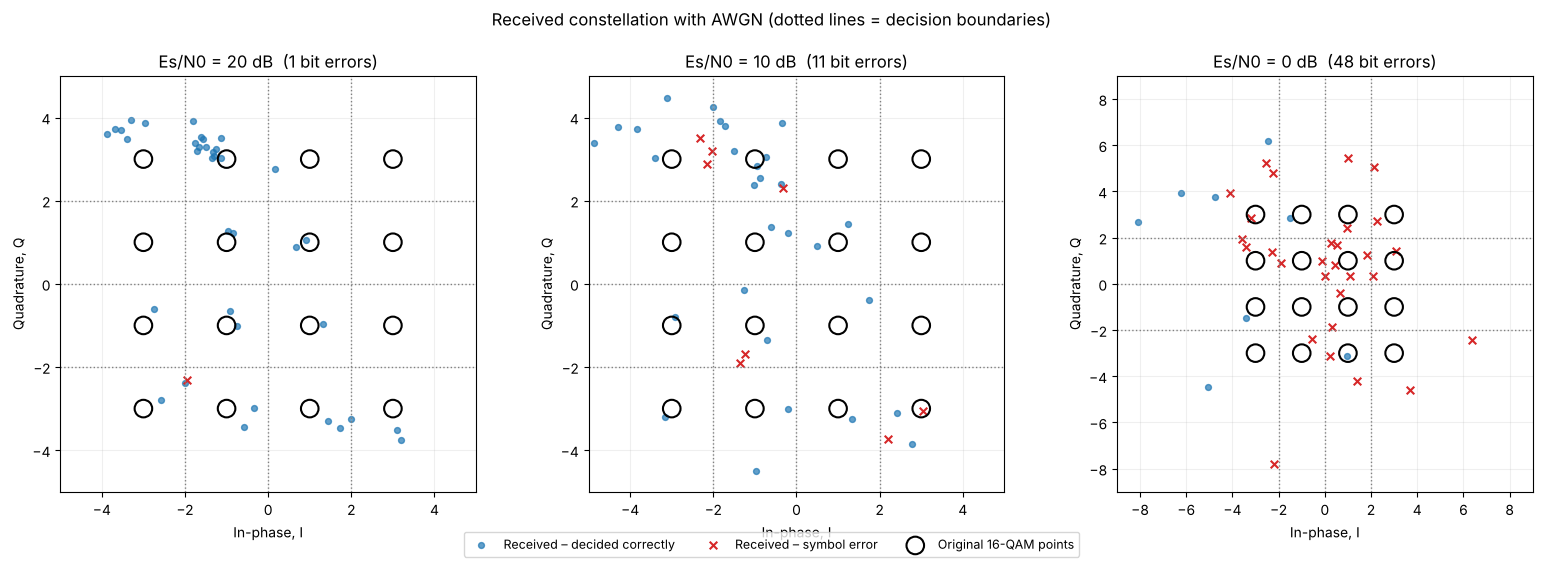

In [19]:
# ---------- 5(b) noisy constellation(s) against the original points ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, snr_db in zip(axes, snr_list_db):
    r = results[snr_db]
    # Received (noisy) points, coloured by whether that symbol was decided correctly.
    ok = nearest_level(r['rx_sym'].real) + 1j*nearest_level(r['rx_sym'].imag) == symbols
    ax.scatter(r['rx_sym'][ok].real,  r['rx_sym'][ok].imag,  s=18, color='tab:blue',
               alpha=0.7, label='Received – decided correctly')
    ax.scatter(r['rx_sym'][~ok].real, r['rx_sym'][~ok].imag, s=30, color='tab:red',
               marker='x', label='Received – symbol error')
    # The ideal reference grid.
    ax.scatter(ref_points.real, ref_points.imag, s=160, facecolors='none',
               edgecolors='black', linewidths=1.5, label='Original 16-QAM points')
    # Decision boundaries at -2, 0, +2 on each axis.
    for th in (-2, 0, 2):
        ax.axvline(th, color='grey', ls=':', lw=1); ax.axhline(th, color='grey', ls=':', lw=1)
    lim = 9 if snr_db == 0 else 5
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.set_xlabel('In-phase, I'); ax.set_ylabel('Quadrature, Q')
    ax.set_title(f'Es/N0 = {snr_db} dB  ({r["bit_errors"]} bit errors)')
    ax.grid(True, alpha=0.2)
# Shared legend below the plots so it doesn't hide any points.
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, fontsize=9)
plt.suptitle('Received constellation with AWGN (dotted lines = decision boundaries)', y=1.0)
plt.tight_layout(rect=(0, 0.06, 1, 0.97)); plt.show()

In [20]:
# ---------- extra sanity check: compare with textbook theory ----------
# For Gray-coded square 16-QAM, each axis is a 4-level PAM. The chance a given axis
# value crosses a boundary is (3/2)*Q(1/sigma): the 2 outer levels have 1 neighbour each,
# the 2 inner levels have 2, which averages to 1.5 boundaries per value. With Gray coding,
# a crossing costs 1 of the 2 bits on that axis, so BER ~ (3/4)*Q(1/sigma).
# NB: this ignores the 0.8-cycle distortion, and 152 bits is a tiny sample, so expect a rough match only.
from math import erfc, sqrt
Qfunc = lambda x: 0.5 * erfc(x / sqrt(2))
for snr_db in snr_list_db:
    sigma = np.sqrt(Es / (2 * 10**(snr_db/10)))
    ber_theory = 0.75 * Qfunc(1/sigma)
    print(f"{snr_db:>2} dB: theory BER ~ {ber_theory:.4f} (~{ber_theory*n_bits:.1f} of {n_bits} bits)"
          f"   measured BER = {results[snr_db]['ber']:.4f}")

20 dB: theory BER ~ 0.0000 (~0.0 of 152 bits)   measured BER = 0.0066
10 dB: theory BER ~ 0.0654 (~9.9 of 152 bits)   measured BER = 0.0724
 0 dB: theory BER ~ 0.2503 (~38.1 of 152 bits)   measured BER = 0.3158


**5(d) Why noisy points sometimes decode as the wrong symbol**

The receiver doesn't know which symbol was sent. It only sees where the received point landed and picks the **nearest valid point**. Equivalently, it checks which square decision region (bounded by the dotted lines at −2, 0, +2) the point falls in. AWGN adds a random offset to I and Q. Neighbouring points are only 2 units apart, so the boundary is just **1 unit** away. Whenever the noise pushes a point more than 1 unit towards a neighbour, the point crosses into the wrong region and the receiver *confidently* picks the wrong symbol. It has no way of telling this has happened.

* At **20 dB**, the noise is small (σ ≈ 0.23) compared with the 1-unit margin, so ideal theory predicts essentially no errors. We still measured **1 bit error** ('Hello**$**from…'). The reason is that the 0.8-cycle distortion had already moved some points up to ~0.8 towards a boundary, leaving only ~0.2 of margin, which is less than 1σ. Those symbols fail first.
* At **10 dB**, the noise (σ ≈ 0.74) is comparable to the margin, so a noticeable fraction of points cross (11 bit errors, BER ≈ 0.072, close to the ~0.065 theory estimate).
* At **0 dB**, the noise (σ ≈ 2.3) is larger than the whole spacing. The clouds around neighbouring points overlap completely and decisions are close to guesses (BER ≈ 0.32; pure guessing would give 0.5).

**Gray coding** helps: the most likely error is a jump to an *adjacent* level, and adjacent levels differ by **one** bit. So most symbol errors cost only 1 bit, not 2 to 4. The text breaks as soon as any single bit is wrong, because a changed bit changes the byte, and so the character. That is why only an error-free run reproduces the exact message.

**Record** (values from the run above, seed = 2026):

| E_s/N_0 | Bit errors | BER = errors / 152 | Text matches? |
|---|---|---|---|
| 20 dB | 1 | 1/152 = 0.0066 | No (`Hello$from the lab.`) |
| 10 dB | 11 | 11/152 = 0.0724 | No |
| 0 dB | 48 | 48/152 = 0.3158 | No (unreadable) |

A single wrong bit is enough to change a character. At 20 dB, one bit in the space byte `00100000` flipped to give `00100100` = `'$'`.

---
## 6. (Extra) Attenuation and Multipath

The submission checklist asks for *"Attenuation and multipath results"*, but the lab sheet gives no question or parameters for them. I've therefore picked simple, clearly stated values and shown both effects in the same style as above.

### 6.1 Attenuation
A real channel scales the signal down: r(t) = α·x(t). The receiver is linear, so the recovered constellation shrinks by the same α. **The decision thresholds (−2, 0, +2) are fixed**, so a shrunk outer point at α·3 can fall inside the ±2 band and get decoded as ±1.

Worked example, α = 0.5: the outer level 3 becomes 1.5, which is < 2, so it decodes as **1**. That's an error. The inner level 1 becomes 0.5, still between 0 and 2, so it stays 1 (correct).

**Fix (automatic gain control):** estimate α and divide it out. A simple estimate compares RMS values: α̂ = rms(received symbols) / rms(ideal constellation), using √10 for ideal 16-QAM. In practice you'd use a known pilot/training sequence instead.

In [21]:
# ---------- 6.1 attenuation experiment ----------
def run_chain(rx_pass, label):
    # Receiver chain reused from Q4: recover -> decide -> bits -> text. Returns a summary.
    rs = recover_symbols(rx_pass, fc, fs, Ns)
    b_all, _ = symbols_to_bits(rs)
    _, txt = bits_to_text(b_all, n_bits)
    errs = int(np.sum(b_all[:n_bits] != bits))
    print(f"{label:<38} bit errors = {errs:>3}, BER = {errs/n_bits:.4f}, match = {txt == message}, text = {txt!r}")
    return rs

alpha = 0.5                                   # 50% amplitude = -6 dB (20*log10(0.5) = -6.02 dB)
rx_att = alpha * tx_passband
rs_att = run_chain(rx_att, f"Attenuated x{alpha} (no AGC)")

# Simple AGC: scale the recovered symbols so their RMS matches the ideal 16-QAM RMS (sqrt(10)).
gain = np.sqrt(np.mean(np.abs(rs_att)**2)) / np.sqrt(10)
print(f"  estimated channel gain alpha_hat = {gain:.3f}")
rs_agc = run_chain(rx_att / gain, f"Attenuated x{alpha} + AGC")

Attenuated x0.5 (no AGC)               bit errors =  42, BER = 0.2763, match = False, text = ']u}}\x7fuww\x7f}uu}uu}uw\x7f'
  estimated channel gain alpha_hat = 0.573
Attenuated x0.5 + AGC                  bit errors =   0, BER = 0.0000, match = True, text = 'Hello from the lab.'


### 6.2 Multipath
With multipath, a delayed, weaker echo arrives on top of the direct signal: r[n] = x[n] + β·x[n − D]. I chose β = 0.4 and D = 25 samples (= 25 × 40 ns = **1 µs**, i.e. ¼ of a symbol). Two things go wrong:
1. **Inter-symbol interference (ISI):** for the first 25 samples of each symbol, the echo still carries the *previous* symbol, so the neighbour leaks in.
2. The echo is delayed by 1 µs, which is a carrier phase shift of 2π·f_c·D/f_s = 2π × 0.2 = 72°. That **rotates** the echo's contribution, mixing I into Q.

Together these smear each point into a cloud, even with no noise, and reduce the margin before any AWGN is added.

Echo delay = 25 samples = 1.0 us; carrier phase of echo = 72 deg
Multipath (beta=0.4, D=25)             bit errors =   1, BER = 0.0066, match = False, text = 'Hello from the lcb.'
Multipath + AWGN (20 dB)               bit errors =   1, BER = 0.0066, match = False, text = 'Hello!from the lab.'


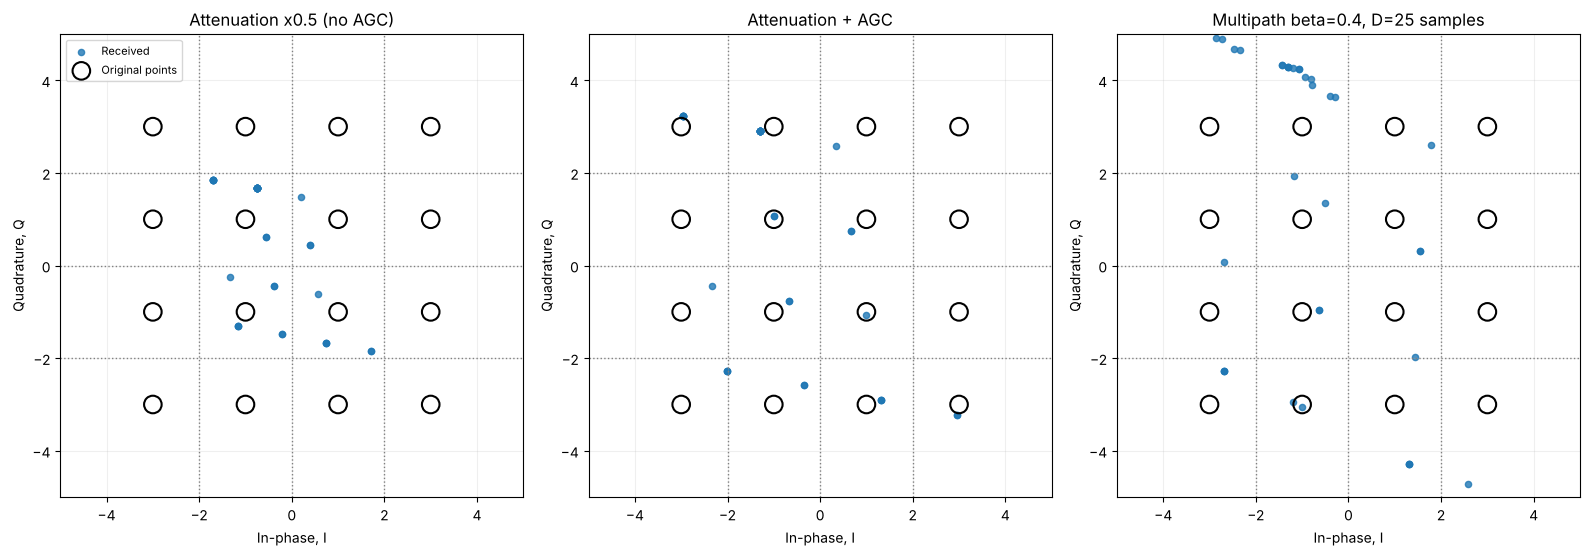

In [22]:
# ---------- 6.2 multipath experiment ----------
beta, D = 0.4, 25                               # echo amplitude and delay in samples
print(f"Echo delay = {D} samples = {D/fs*1e6:.1f} us; carrier phase of echo = {360*fc*D/fs:.0f} deg")
echo = np.concatenate([np.zeros(D), tx_passband[:-D]])   # x[n-D], with zeros before the signal starts
rx_mp = tx_passband + beta * echo
rs_mp = run_chain(rx_mp, f"Multipath (beta={beta}, D={D})")

# Multipath plus moderate noise, to show the combined effect.
rx_mp_noisy = add_passband_awgn(rx_mp, symbols, Ns, 20, seed=2026)
rs_mp_n = run_chain(rx_mp_noisy, "Multipath + AWGN (20 dB)")

# Plot: original vs attenuated vs multipath constellations.
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
cases = [(rs_att, f'Attenuation x{alpha} (no AGC)'), (rs_agc, 'Attenuation + AGC'),
         (rs_mp, f'Multipath beta={beta}, D={D} samples')]
for ax, (rs, title) in zip(axes, cases):
    ax.scatter(rs.real, rs.imag, s=20, color='tab:blue', alpha=0.8, label='Received')
    ax.scatter(ref_points.real, ref_points.imag, s=160, facecolors='none',
               edgecolors='black', linewidths=1.5, label='Original points')
    for th in (-2, 0, 2):
        ax.axvline(th, color='grey', ls=':', lw=1); ax.axhline(th, color='grey', ls=':', lw=1)
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5); ax.set_aspect('equal')
    ax.set_xlabel('In-phase, I'); ax.set_ylabel('Quadrature, Q'); ax.set_title(title)
    ax.grid(True, alpha=0.2)
axes[0].legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation**
* **Attenuation** (×0.5) without gain correction pulls the outer points inside the ±2 thresholds. The outer levels (±3) are then misread as ±1, which corrupts the text (42 bit errors) even though **no noise was added**. Rescaling the received symbols (AGC) restores the grid, and the message comes back with 0 errors. (The estimated gain is 0.57 rather than 0.50 because this message's E_s is 10.8, not the ideal 10, but that is close enough.)
* **Multipath** smears and rotates the constellation. Every symbol now depends partly on the one before it (ISI). Whether the text survives depends on how strong and how long the echo is. Here a fairly mild echo (β = 0.4, 1 µs) already causes **1 bit error with no noise at all** ('lab' → 'lcb'). The cloud spread eats into the decision margin, so adding noise on top makes errors much more likely. Real systems fight this with **equalisers**, **guard intervals / cyclic prefixes** (as in OFDM), or by making symbols much longer than the delay spread.

---
## Summary

| Item | Result |
|---|---|
| Bytes / bits | 19 bytes / 152 bits |
| Symbols | 38 (4 bits each) |
| N_s | 100 samples per symbol |
| Symbol rate / bit rate | 250 kBd / 1 Mbit/s |
| Carrier cycles per symbol | 0.8 (not whole, so the receiver output is slightly distorted, but still decodes correctly) |
| Ideal channel | 0 bit errors, text recovered exactly |
| Noise (20 / 10 / 0 dB) | 1 / 11 / 48 bit errors; BER 0.0066 / 0.072 / 0.316; text never exact |
| Attenuation ×0.5 | 42 errors without AGC, 0 with AGC |
| Multipath β=0.4, 1 µs | 1 error even without noise |